# Pipeline de análise de imagens de RX normal, pneumonia ou COVID19 visando emissão de laudos / diagnóstico automatizados a serem confirmados pelo profissional de medicina

### Rede Neural Xception

In [1]:
import pandas as pd
import numpy as np
import os
import shutil
import matplotlib.pyplot as plt
import math
import tensorflow as tf
import datetime
import keras
from keras import models
from keras import layers
from keras import optimizers
from keras.models import Sequential
from keras.layers import Dense, Conv2D , SeparableConv2D, MaxPool2D , Flatten , Dropout , BatchNormalization, Activation
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img
from keras.callbacks import ReduceLROnPlateau
from keras import backend as K
from keras import optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, recall_score, precision_score, confusion_matrix, f1_score, accuracy_score


In [2]:
df = pd.DataFrame(columns =['class', 'directory'])
for path, names, filenames in os.walk('dataset/NORMAL/'):
    for filename in filenames:
        df.loc[-1] = ["NORMAL", ('NORMAL/' + filename)]
        df.index = df.index + 1
        df = df.sort_index()
for path, names, filenames in os.walk('dataset/COVID/'):
    for filename in filenames:
        df.loc[-1] = ["COVID", ('COVID/' + filename)]
        df.index = df.index + 1
        df = df.sort_index()
for path, names, filenames in os.walk('dataset/PNEUMONIA/'):
    for filename in filenames:
        df.loc[-1] = ["PNEUMONIA", ('PNEUMONIA/' + filename)]
        df.index = df.index + 1
        df = df.sort_index()

In [3]:
df

,class,directory
0,PNEUMONIA,PNEUMONIA/PNEUMONIA_999.png
1,PNEUMONIA,PNEUMONIA/PNEUMONIA_998.png
2,PNEUMONIA,PNEUMONIA/PNEUMONIA_997.png
3,PNEUMONIA,PNEUMONIA/PNEUMONIA_996.png
4,PNEUMONIA,PNEUMONIA/PNEUMONIA_995.png
...,...,...
5223,NORMAL,NORMAL/NORMAL_1001.png
5224,NORMAL,NORMAL/NORMAL_1000.png
5225,NORMAL,NORMAL/NORMAL_100.png
5226,NORMAL,NORMAL/NORMAL_10.png


In [4]:
df_y = df['class']
df_x = df['directory']

In [5]:
df_x

0       PNEUMONIA/PNEUMONIA_999.png
1       PNEUMONIA/PNEUMONIA_998.png
2       PNEUMONIA/PNEUMONIA_997.png
3       PNEUMONIA/PNEUMONIA_996.png
4       PNEUMONIA/PNEUMONIA_995.png
                   ...             
5223         NORMAL/NORMAL_1001.png
5224         NORMAL/NORMAL_1000.png
5225          NORMAL/NORMAL_100.png
5226           NORMAL/NORMAL_10.png
5227              NORMAL/NORMAL.png
Name: directory, Length: 5228, dtype: str

In [6]:
df_y.value_counts()

class
NORMAL       1802
PNEUMONIA    1800
COVID        1626
Name: count, dtype: int64

In [7]:
X_train, X_test, y_train, y_test = train_test_split(df_x, df_y, stratify= df_y, test_size=0.20, random_state=42)

In [8]:
y_train.value_counts()

class
NORMAL       1441
PNEUMONIA    1440
COVID        1301
Name: count, dtype: int64

In [9]:
test = pd.concat([X_test, y_test], axis = 1)
test.head()

,directory,class
1309,PNEUMONIA/PNEUMONIA_144.png,PNEUMONIA
846,PNEUMONIA/PNEUMONIA_236.png,PNEUMONIA
4801,NORMAL/NORMAL_1382.png,NORMAL
3125,COVID/COVID_1269.png,COVID
156,PNEUMONIA/PNEUMONIA_858.png,PNEUMONIA


In [10]:
train = pd.concat([X_train, y_train], axis = 1)
train.head()

,directory,class
1504,PNEUMONIA/PNEUMONIA_1264.png,PNEUMONIA
1736,PNEUMONIA/PNEUMONIA_1055.png,PNEUMONIA
5058,NORMAL/NORMAL_1150.png,NORMAL
500,PNEUMONIA/PNEUMONIA_548.png,PNEUMONIA
1377,PNEUMONIA/PNEUMONIA_1379.png,PNEUMONIA


In [11]:
def copy_images(df, directory):
    input_path = 'dataset'
    output_path = "./out/" + directory

    # Se algum arquivo antigo existe no path de saída, ele é removido
    if os.path.exists(output_path):
        shutil.rmtree(output_path)

    # Criando a pasta dentro do path de saída
    if not os.path.exists(output_path):
        os.makedirs(output_path)

    # Criando três subpastas
    classes = ['NORMAL', 'COVID', 'PNEUMONIA']
    for c in classes:
        if not os.path.exists(output_path + '/' + c):
            os.makedirs(output_path + '/' + c)

   # O dataframe original contém um diretório para cada linha, esses diretórios são deslocados do diretório de entrada para o diretório de saída
    for i, row in df.iterrows():
        path_from = "{}/{}".format(input_path, row['directory'])
        path_to = "{}/{}".format(output_path, row['directory'])
        shutil.copy(path_from, path_to)

In [12]:
# Move as imagens de teste e de treino do diretório de entrada para o diretório de saída
copy_images(test, 'test')
copy_images(train, 'train')

In [13]:
print(len(os.listdir('./out/train/NORMAL')))
print(len(os.listdir('./out/train/COVID')))
print(len(os.listdir('./out/train/PNEUMONIA')))

1441
1301
1440


In [14]:
print(len(os.listdir('./out/test/NORMAL')))
print(len(os.listdir('./out/test/COVID')))
print(len(os.listdir('./out/test/PNEUMONIA')))

361
325
360


In [15]:
# Treinando os dados
train_datagen = ImageDataGenerator(
        rescale=1./255,
        rotation_range=10,
        zoom_range=0.4,
        horizontal_flip=True,
        validation_split=0.01
        )

train_generator = train_datagen.flow_from_directory(
        './out/train',
        target_size=(100, 100),
        batch_size=32,
        class_mode='categorical',
        subset='training'
        )

Found 4141 images belonging to 3 classes.


In [16]:
# Validando os dados
val_generator = train_datagen.flow_from_directory(
        './out/train',
        target_size=(100, 100),
        batch_size=32,
        class_mode='categorical',
        subset='validation')

Found 41 images belonging to 3 classes.


In [17]:
# Testando os dados
test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_directory(
        './out/test',
        target_size=(100, 100),
        batch_size=32,
        class_mode='categorical')

Found 1046 images belonging to 3 classes.


In [18]:
# Aplicando o modelo Xception pré-treinado
xception=tf.keras.applications.Xception(input_shape=(100,100,3),
                             include_top=False,
                             weights='imagenet')

# Congelando as camadas (layers)
for layer in xception.layers:
    layer.trainable=False

In [19]:
last_layer=xception.layers[-1]
last_output = last_layer.output

In [20]:
x=layers.Flatten()(last_output)

# Adicionando uma camada extra
x=layers.Dense(256,activation='relu')(x)

# Camada de saída
x=layers.Dense(3,activation='softmax')(x)

xception_model=keras.Model(xception.input,x)

In [21]:
xception_model.compile(optimizer='adam',
              loss='categorical_crossentropy',
               metrics=['accuracy'])

In [22]:
xception_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 49, 49,    │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 49, 49,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 49, 49,    │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 47, 47,    │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 47, 47,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 47, 47,    │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 47, 47,    │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 47, 47,    │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 47, 47,    │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 47, 47,    │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 47, 47,    │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 24, 24,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 24, 24,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 24, 24,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 24, 24,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 24, 24,    │          0 │ add[0][0]       

 Total params: 25,581,099 (97.58 MB)

 Trainable params: 4,719,619 (18.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

In [23]:
keras.utils.plot_model(xception_model)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


In [24]:
history_xception=xception_model.fit(train_generator,
                                    validation_data = val_generator,
                                    steps_per_epoch = 40,
                                    epochs = 5)

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 32s 715ms/step - accuracy: 0.7232 - loss: 2.5076 - val_accuracy: 0.7073 - val_loss: 1.3853
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 590ms/step - accuracy: 0.8031 - loss: 0.8015 - val_accuracy: 0.9512 - val_loss: 0.2309
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 21s 542ms/step - accuracy: 0.8320 - loss: 0.5367 - val_accuracy: 0.9512 - val_loss: 0.2330
Epoch 4/5
10/40 ━━━━━━━━━━━━━━━━━━━━ 13s 462ms/step - accuracy: 0.8594 - loss: 0.4028

c:\Users\alden\tcc-reproducao\cnn_artigo_tcc\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 121ms/step - accuracy: 0.8594 - loss: 0.4028 - val_accuracy: 0.8293 - val_loss: 0.4981
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 20s 485ms/step - accuracy: 0.8609 - loss: 0.4320 - val_accuracy: 0.9512 - val_loss: 0.3122


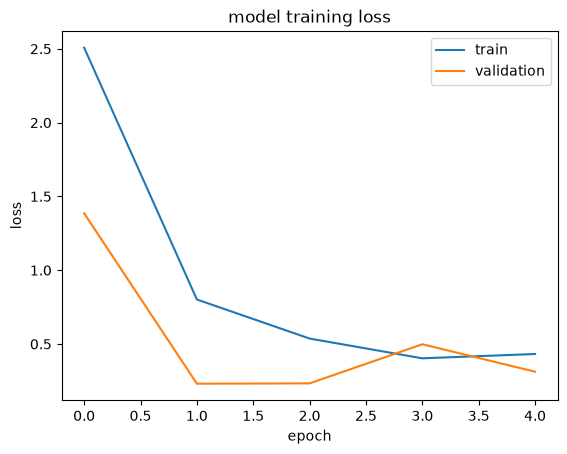

In [25]:
plt.plot(history_xception.history['loss'])
plt.plot(history_xception.history['val_loss'])
plt.title('model training loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

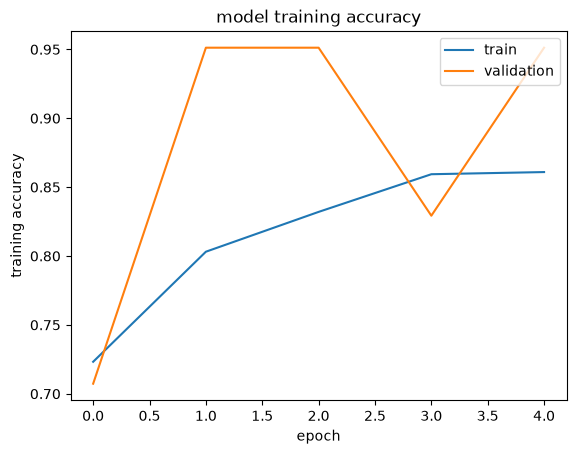

In [26]:
plt.plot(history_xception.history['accuracy'])
plt.plot(history_xception.history['val_accuracy'])
plt.title('model training accuracy')
plt.ylabel('training accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper right')
plt.show()

In [27]:
# Avaliando os dados do teste
x = xception_model.evaluate(test_generator)

33/33 ━━━━━━━━━━━━━━━━━━━━ 18s 534ms/step - accuracy: 0.8623 - loss: 0.4396


In [28]:
print(f'Testing loss: {x[0]}')
print(f'Testing accuracy: {x[1]}')

Testing loss: 0.4395825266838074
Testing accuracy: 0.8623327016830444


In [29]:
# Prevendo a classe de cada imagem e armazenando em um array
y_predictions=[]
for img in os.listdir('./out/test/NORMAL'):
    img = load_img('./out/test/NORMAL/'+img,target_size=(100,100))
    img = img_to_array(img)
    img = np.expand_dims(img, axis = 0)
    result = xception_model.predict(img/255.0)[0]
    y_predictions.append(np.argmax(result))

for img in os.listdir("./out/test/COVID"):
    img = load_img('./out/test/COVID/'+img,target_size=(100,100))
    img = img_to_array(img)
    img = np.expand_dims(img, axis = 0)
    result = xception_model.predict(img/255.0)[0]
    y_predictions.append(np.argmax(result))

for img in os.listdir("./out/test/PNEUMONIA"):
    img = load_img('./out/test/PNEUMONIA/'+img,target_size=(100,100))
    img = img_to_array(img)
    img = np.expand_dims(img, axis = 0)
    result = xception_model.predict(img/255.0)[0]
    y_predictions.append(np.argmax(result))

y_predictions=np.array(y_predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 894ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━

In [30]:
test_generator.class_indices

{'COVID': 0, 'NORMAL': 1, 'PNEUMONIA': 2}

In [31]:
# Cálculo do precision, recall and f1 score para todas as classes
print(classification_report(test_generator.classes,y_predictions))

              precision    recall  f1-score   support

           0       0.03      0.03      0.03       325
           1       0.10      0.12      0.11       361
           2       0.93      0.71      0.81       360

    accuracy                           0.30      1046
   macro avg       0.35      0.29      0.31      1046
weighted avg       0.36      0.30      0.32      1046



In [32]:
print(confusion_matrix(test_generator.classes,y_predictions))

[[  9 311   5]
 [305  43  13]
 [ 10  93 257]]


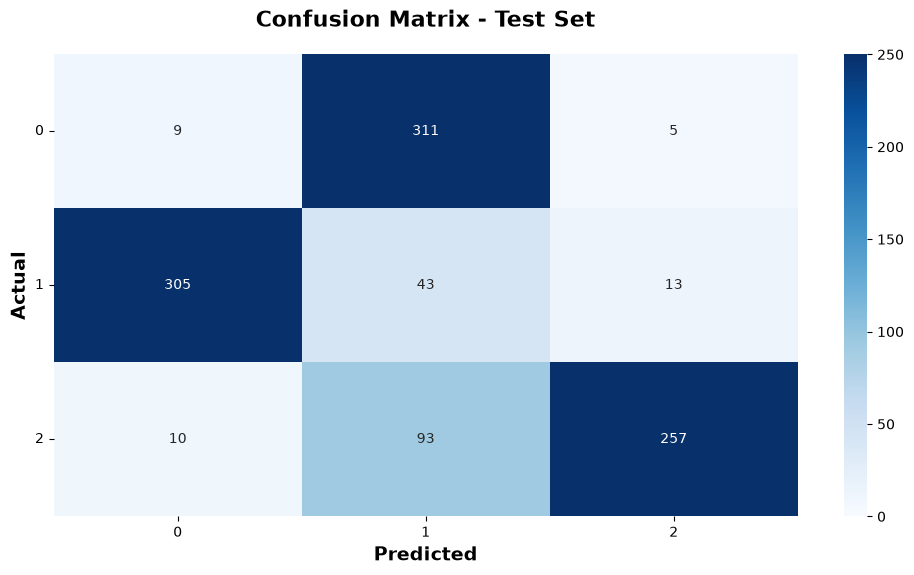

In [33]:
import seaborn as sns


plt.figure(figsize=(12, 6))
ax = sns.heatmap(confusion_matrix(test_generator.classes,y_predictions), annot = True, fmt = 'g' ,vmin = 0, vmax = 250,cmap = 'Blues')
ax.set_xlabel('Predicted',fontsize = 14,weight = 'bold')
ax.set_xticklabels(ax.get_xticklabels(),rotation =0);

ax.set_ylabel('Actual',fontsize = 14,weight = 'bold')
ax.set_yticklabels(ax.get_yticklabels(),rotation =0);
ax.set_title('Confusion Matrix - Test Set',fontsize = 16,weight = 'bold',pad=20);